# FirePath AI on SageMaker

Run this in a **JupyterLab space** (Unified Studio: Build → JupyterLab) or a **notebook instance**, set to **`ml.g4dn.xlarge`** (T4 GPU) with a GPU image, ~50 GB storage. The serverless "Notebooks" page has no GPU.

Upload your files anywhere in the JupyterLab file browser (e.g. the `shared` folder); the notebook finds them:
- `firepath.zip` (optional — the notebook clones from GitHub first)
- `D-Fire.zip`
- a `videos/` folder with your evaluation videos, `videos.csv` and `calib.csv` (step 4)

Small files: drag them into the file browser. Big files (D-Fire): upload to S3 and use the S3 line in step 2.

**Stop the space / instance when you're done.** It bills every hour it's running, even idle.

In [1]:
import sys, os
# notebook instance -> /home/ec2-user/SageMaker ; Studio / Unified Studio JupyterLab space -> /home/sagemaker-user
BASE = next((p for p in ['/home/ec2-user/SageMaker', '/home/sagemaker-user'] if os.path.isdir(p)), os.path.expanduser('~'))
print('Working folder:', BASE)
import glob
def find_upload(name):
    hits = sorted(glob.glob(f'{BASE}/**/{name}', recursive=True), key=len)
    return hits[0] if hits else None
PY = sys.executable          # use the kernel's python for every command below
print('Python:', PY)
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch; print('CUDA available:', torch.cuda.is_available())

Working folder: /home/sagemaker-user
Python: /opt/conda/bin/python
name, memory.total [MiB]
Tesla T4, 15360 MiB
CUDA available: True


## 0. Get the project

In [2]:
import glob, subprocess
PROJ = f'{BASE}/firepath'
if not os.path.exists(f'{PROJ}/requirements.txt'):
    r = subprocess.run(['git', 'clone', '-q', 'https://github.com/Aditi-Nandiraju/Firepath-CV.git', PROJ])
    if r.returncode != 0:
        z = find_upload('firepath.zip')
        if not z:
            raise SystemExit('Clone failed and firepath.zip not found under ' + BASE)
        subprocess.run(['unzip', '-q', '-o', z, '-d', BASE], check=True)
if not os.path.exists(f'{PROJ}/requirements.txt'):   # zip extracted under another name
    PROJ = os.path.dirname(sorted(glob.glob(f'{BASE}/**/requirements.txt', recursive=True), key=len)[0])
print('Project at', PROJ)
%cd $PROJ

Project at /home/sagemaker-user/firepath
/home/sagemaker-user/firepath


In [12]:
%pip install -q -r requirements.txt
# SageMaker's Amazon Linux lacks the GUI libraries the normal OpenCV needs; swap to the headless build if import fails
try:
    import cv2
except ImportError:
    !{PY} -m pip uninstall -y -q opencv-python
    %pip install -q opencv-python-headless
print('Restart the kernel once (Kernel → Restart Kernel) if cv2 still fails, then re-run from the top.')

Note: you may need to restart the kernel to use updated packages.
Restart the kernel once (Kernel → Restart Kernel) if cv2 still fails, then re-run from the top.


## 1. Quick test of the simulation (placeholder numbers, NOT results)

               policy  success_rate  fire_casualty_rate  smoke_exposure_s  detour_ratio  evac_time_s  route_flips
               static         0.901               0.099            10.139         1.000       56.969        0.000
        threshold@0.5         0.970               0.030            13.322         1.097       65.346        0.442
       threshold@0.25         0.971               0.029            14.100         1.153       68.043        0.619
          latched@0.5         0.960               0.040            13.928         1.146       67.731        0.270
       voting2of3@0.5         0.975               0.025            13.625         1.081       64.284        0.218
        confidence@40         0.951               0.049            11.111         1.026       60.141        0.071
 confidence@40+ema0.5         0.941               0.059            10.617         1.015       59.328        0.034
confidence@160+ema0.5         0.974               0.026            11.697         1.075 

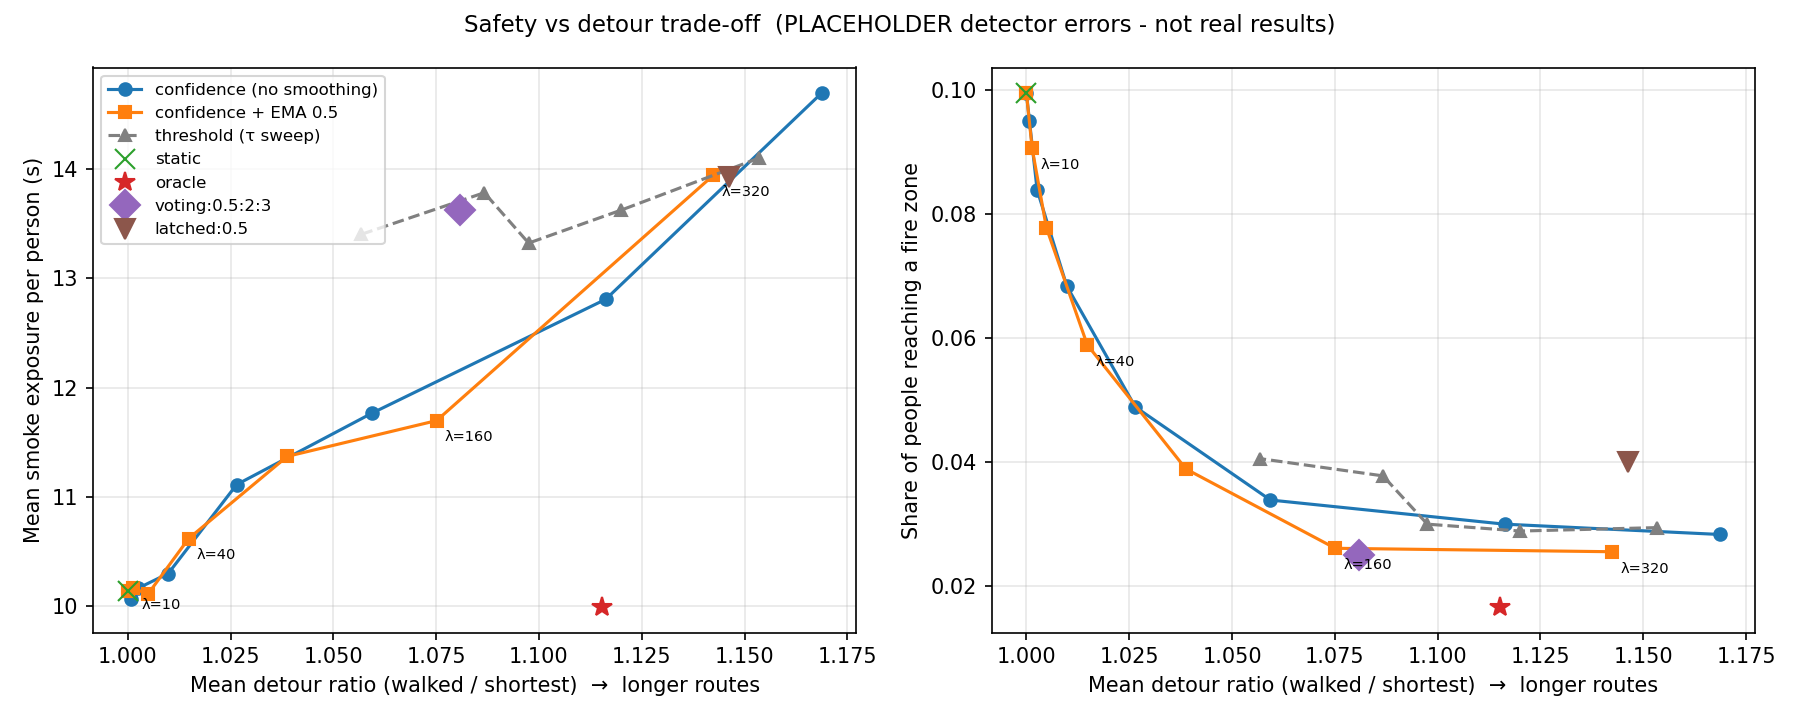

In [13]:
!{PY} -m firepath.experiments --scenarios 60 --skip-ablation --out results_demo
from IPython.display import Image, display
display(Image('results_demo/tradeoff.png'))

saved results_demo/route_example.png  (seed=9, step=4, room=F3_R0)


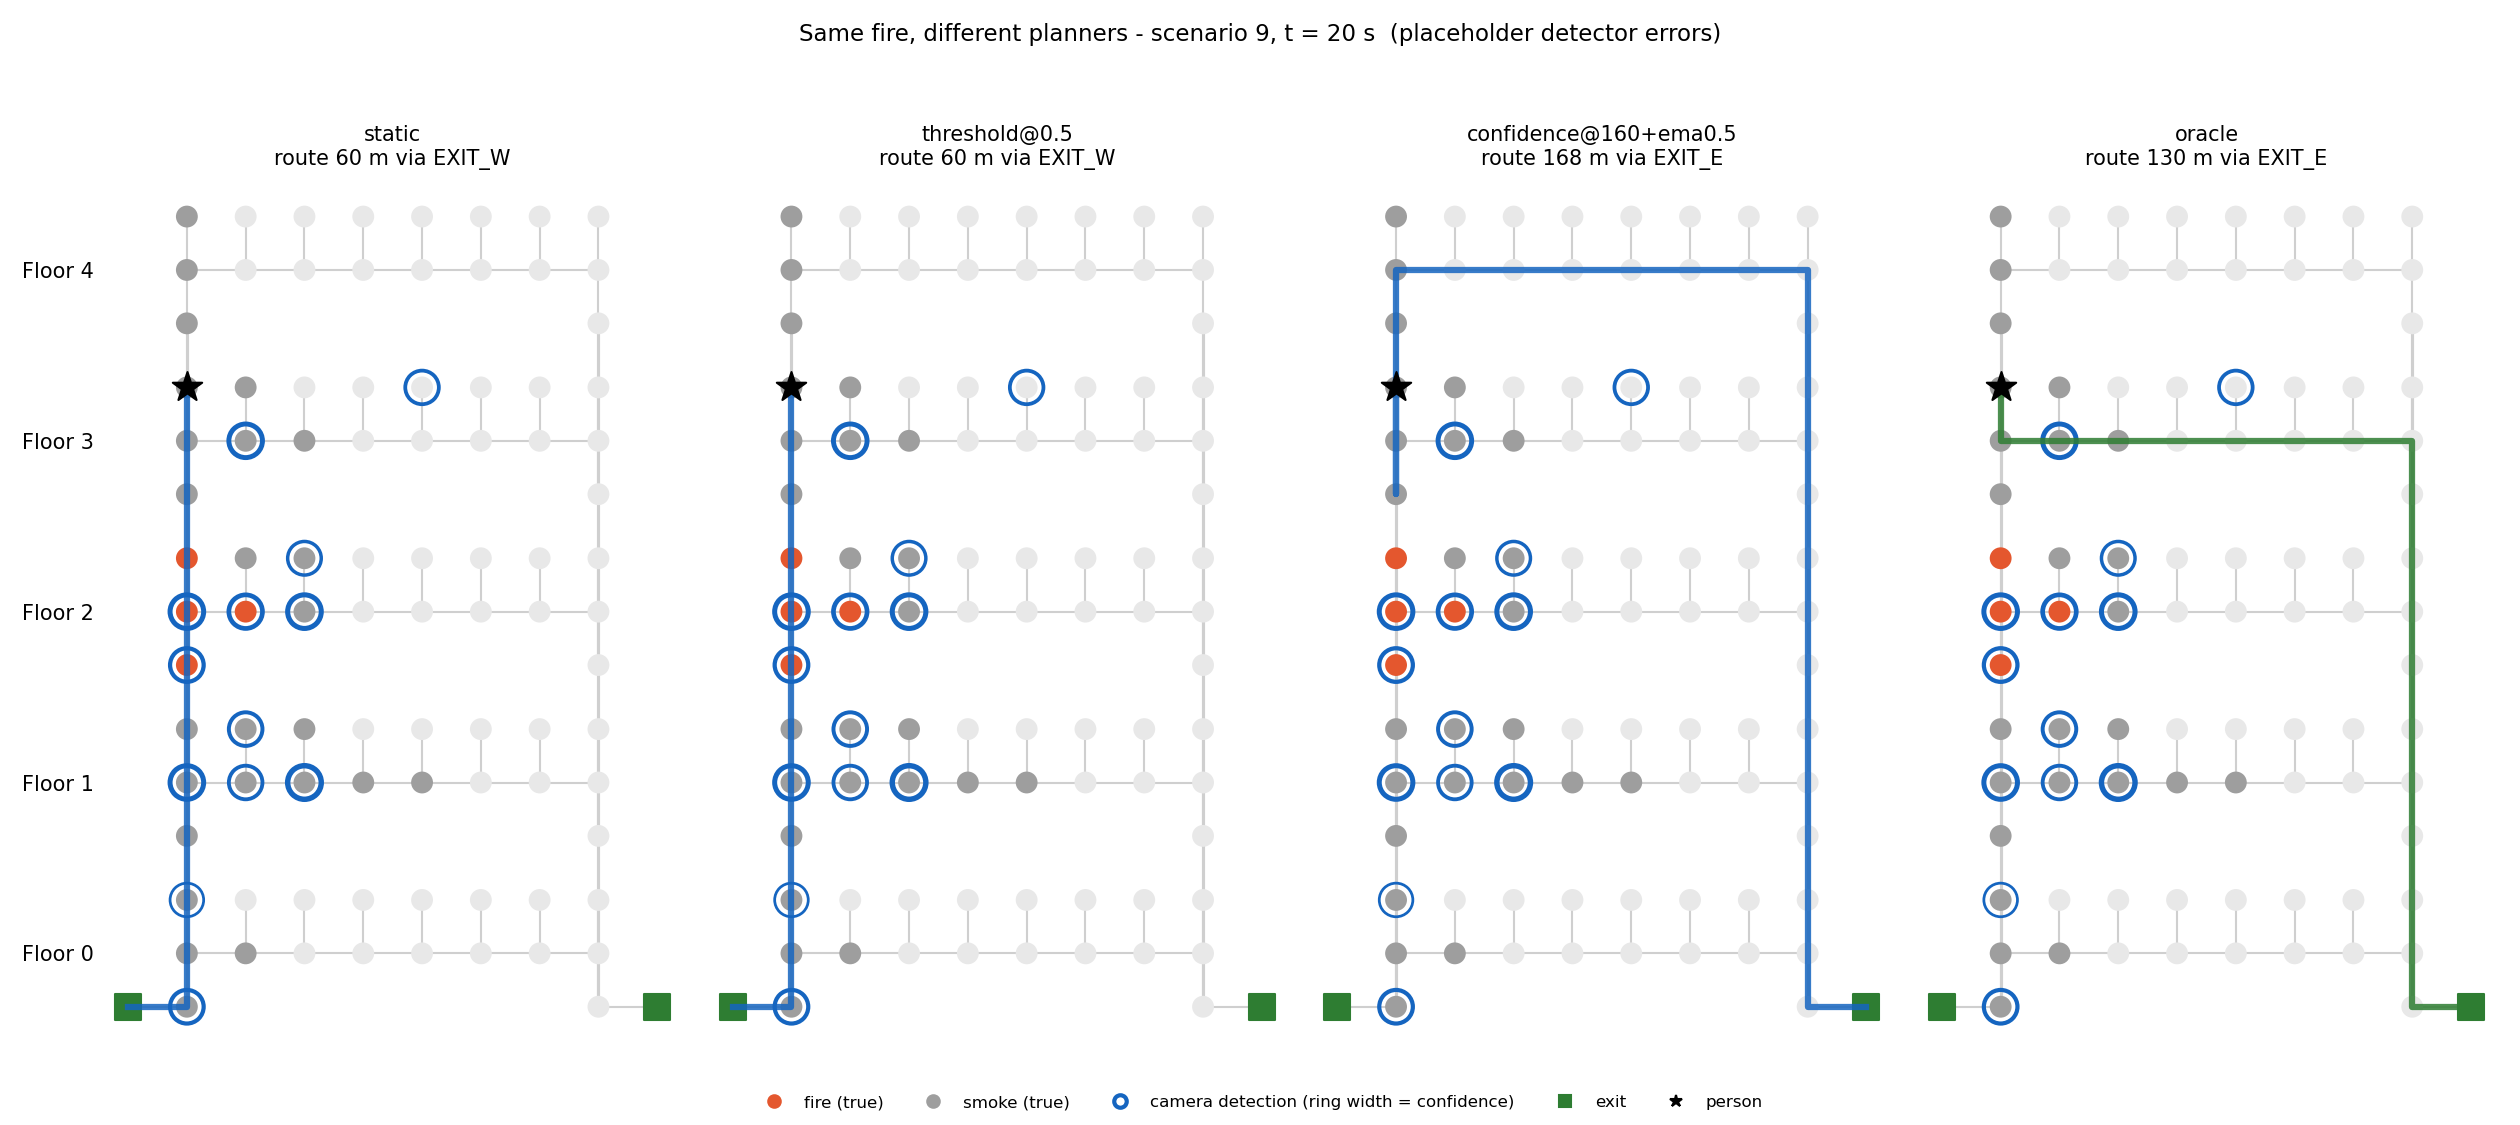

In [14]:
!{PY} -m firepath.visualize --find-interesting --out results_demo/route_example.png
display(Image('results_demo/route_example.png'))

## 2. Get D-Fire
Either drag `D-Fire.zip` into the top folder, or upload it to S3 and fill in `S3_DFIRE`.

In [7]:
%pip install -q gdown
!cd $BASE && gdown --folder https://drive.google.com/drive/folders/1DWgsQLVgkkLM8m-VcugHNpD5WYDbjYp5
!ls -la $BASE

Note: you may need to restart the kernel to use updated packages.
Retrieving folder contents
Failed to retrieve folder contents for folder ID: 1DWgsQLVgkkLM8m-VcugHNpD5WYDbjYp5 (status code 404). You may need to change the permission to 'Anyone with the link', or have had many accesses. Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.
total 16
drwx------. 15 sagemaker-user nogroup 4096 Nov 19 09:59 .
drwxrwxrwx.  1 root           root      28 Oct 30 00:21 ..
drwxr-xr-x.  7 sagemaker-user users     97 Nov 19 09:55 .aws
-rw-r--r--.  1 sagemaker-user users    401 Sep 26 21:49 .bashrc
drwxr-xr-x.  8 sagemaker-user users     82 Nov 19 10:01 .cache
drwxr-xr-x.  3 sagemaker-user users     58 Sep 26 21:49 .config
-rw-r--r--.  1 sagemaker-user users    186 Nov 19 09:55 .gitconfig
drwxr-xr-x.  3 sagemaker-user users     29 Sep 26 21:49 .ipython
drwxr-xr-x.  3 sagemaker-user users     61 Nov 19 09:55 .jupyter
drwxr-xr-x.  3 sagemaker-user users     22 Sep 26 21:49 .kiro
drwx

In [10]:
!rm -f ~/D-Fire.zip
!ls -lh ~/shared/D-Fire.zip

-rw-r--r--. 1 sagemaker-user users 8.0M Nov 19 10:42 /home/sagemaker-user/shared/D-Fire.zip


In [9]:
import base64
share = 'https://1drv.ms/u/c/c0bd25b6b048b01d/EbLgD7bES4FDvUN37Grxn8QBF5gIBBc7YV2qklF08GCiBw'
token = 'u!' + base64.urlsafe_b64encode(share.encode()).decode().rstrip('=')
url = f'https://api.onedrive.com/v1.0/shares/{token}/root/content'
!wget -q --show-progress -O ~/D-Fire.zip "{url}"
!ls -lh ~/D-Fire.zip
!file ~/D-Fire.zip

-rw-r--r--. 1 sagemaker-user users 0 Nov 19 10:05 /home/sagemaker-user/D-Fire.zip
/bin/bash: line 1: file: command not found


In [15]:
S3_DFIRE = ''   # e.g. 's3://my-bucket/D-Fire.zip'  (leave empty if you uploaded the zip directly)
DFIRE = f'{BASE}/D-Fire'
ZIP = find_upload('D-Fire.zip')
if S3_DFIRE and not ZIP:
    ZIP = f'{BASE}/D-Fire.zip'
    !aws s3 cp $S3_DFIRE $ZIP
if not os.path.isdir(DFIRE):
    if not ZIP:
        raise SystemExit('D-Fire.zip not found - upload it or set S3_DFIRE')
    !unzip -q -o "$ZIP" -d $DFIRE
!ls $DFIRE

[/home/sagemaker-user/shared/D-Fire.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /home/sagemaker-user/shared/D-Fire.zip or
        /home/sagemaker-user/shared/D-Fire.zip.zip, and cannot find /home/sagemaker-user/shared/D-Fire.zip.ZIP, period.
ls: cannot access '/home/sagemaker-user/D-Fire': No such file or directory


Check which class id is fire and which is smoke. The output tells you what to pass as `--names`. If `ls` shows a single sub-folder, set `DFIRE` to that sub-folder.

In [ ]:
!{PY} detection/check_dataset.py --root $DFIRE

In [16]:
%pip install -q -U huggingface_hub
from huggingface_hub import snapshot_download
DFIRE = os.path.expanduser('~/D-Fire')
snapshot_download('hanvithSai/gavin-dfire-raw', repo_type='dataset', local_dir=DFIRE, max_workers=16)
!for s in train test; do echo $s $(ls $DFIRE/$s/images | wc -l) images; done

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 2.2.1 requires huggingface-hub<1.0.0,>=0.1.0, but you have huggingface-hub 2.4.0 which is incompatible.
tokenizers 0.22.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.4.0 which is incompatible.
transformers 4.57.6 requires huggingface-hub<1.0,>=0.34.0, but you have huggingface-hub 2.4.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

ls: cannot access '/train/images': No such file or directory
train 0 images
ls: cannot access '/test/images': No such file or directory
test 0 images


In [18]:
!ls -lah ~/D-Fire
!find ~/D-Fire -maxdepth 3 -not -path '*/.cache*' | head -40

total 3.1G
drwxr-xr-x.  3 sagemaker-user users    111 Nov 19 10:46 .
drwx------. 16 sagemaker-user nogroup 4.0K Nov 19 10:46 ..
drwxr-xr-x.  3 sagemaker-user users     25 Nov 19 10:46 .cache
-rw-r--r--.  1 sagemaker-user users   2.5K Nov 19 10:46 .gitattributes
-rw-r--r--.  1 sagemaker-user users   1.8K Nov 19 10:46 MANIFEST.md
-rw-r--r--.  1 sagemaker-user users   1.8K Nov 19 10:46 README.md
-rw-r--r--.  1 sagemaker-user users   611M Nov 19 10:46 test.tar
-rw-r--r--.  1 sagemaker-user users   2.5G Nov 19 10:46 train.tar
/home/sagemaker-user/D-Fire
/home/sagemaker-user/D-Fire/MANIFEST.md
/home/sagemaker-user/D-Fire/.gitattributes
/home/sagemaker-user/D-Fire/README.md
/home/sagemaker-user/D-Fire/test.tar
/home/sagemaker-user/D-Fire/train.tar


In [19]:
!cd ~/D-Fire && tar -tf train.tar | head -3 && tar -tf test.tar | head -3
!cd ~/D-Fire && tar -xf train.tar && tar -xf test.tar
!cat ~/D-Fire/MANIFEST.md
import glob
for d in sorted(glob.glob(os.path.expanduser('~/D-Fire/*/*/'))):
    print(d, len(os.listdir(d)), 'files')

tar: ._train
Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: train/
train/._.DS_Store
Ignoring unknown extended header keyword 'SCHILY.fflags'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.FinderInfo'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCH

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCH

In [22]:
!find ~/D-Fire -name '._*' -delete
import glob
for d in sorted(glob.glob(os.path.expanduser('~/D-Fire/*/*/'))):
    print(d, len(os.listdir(d)), 'files')
!rm -f ~/D-Fire/train.tar ~/D-Fire/test.tar

/home/sagemaker-user/D-Fire/test/images/ 4306 files
/home/sagemaker-user/D-Fire/test/labels/ 4306 files
/home/sagemaker-user/D-Fire/train/images/ 17221 files
/home/sagemaker-user/D-Fire/train/labels/ 17221 files


## 3. Fine-tune YOLO (a few hours)
Runs in the background and logs to `train.log`, so it keeps going if you close the browser. Change `--names` if step 2 said so; try `EPOCHS = 10` first to test.

In [28]:
EPOCHS = 50   # quick test first; change to 50 for the real run
!{PY} detection/train_yolo.py --root $DFIRE --names smoke fire --epochs $EPOCHS --model yolov8n.pt 2>&1 | tee train.log

Reusing existing split at /home/sagemaker-user/D-Fire_split
Ultralytics 8.4.215 🚀 Python-3.12.15 torch-2.8.0 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/sagemaker-user/D-Fire_split/dfire.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.

In [29]:
import glob
BEST = max(glob.glob('runs/**/weights/best.pt', recursive=True), key=os.path.getmtime)
print('Weights:', BEST)
!mkdir -p $BASE/saved && cp $BEST $BASE/saved/best.pt && ls -lh $BASE/saved/
!grep -E "epochs completed|batch=" train.log | head -3

Weights: runs/detect/runs/firepath/train/weights/best.pt
total 6.3M
-rw-r--r--. 1 sagemaker-user users 6.3M Nov 19 12:25 best.pt
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/sagemaker-user/D-Fire_split/dfire.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=

Once training has finished (log shows the final results), keep a copy of the weights:

In [30]:
!mkdir -p ~/videos && cd ~/videos && wget -q --show-progress -O fire.zip "https://zenodo.org/records/836749/files/fire_videos.1406.zip?download=1" && wget -q --show-progress -O smoke.zip "https://zenodo.org/records/836749/files/smoke_videos.1407.zip?download=1"
!cd ~/videos && unzip -q -o fire.zip && unzip -q -o smoke.zip && rm -f fire.zip smoke.zip
!find ~/videos -type f -not -name '._*' | sort
!cat configs/videos_template.csv

fire.zip            100%[===================>] 593.83M  2.38MB/s    in 3m 18s  
smoke.zip           100%[===================>] 188.44M  2.72MB/s    in 99s     
/home/sagemaker-user/videos/neg/negsVideo1.858.avi
/home/sagemaker-user/videos/neg/negsVideo10.1072.avi
/home/sagemaker-user/videos/neg/negsVideo11.1073.avi
/home/sagemaker-user/videos/neg/negsVideo12.1074.avi
/home/sagemaker-user/videos/neg/negsVideo13.1075.avi
/home/sagemaker-user/videos/neg/negsVideo14.1076.avi
/home/sagemaker-user/videos/neg/negsVideo15.1078.avi
/home/sagemaker-user/videos/neg/negsVideo16.1077.avi
/home/sagemaker-user/videos/neg/negsVideo2.859.avi
/home/sagemaker-user/videos/neg/negsVideo3.860.avi
/home/sagemaker-user/videos/neg/negsVideo4.861.avi
/home/sagemaker-user/videos/neg/negsVideo5.862.avi
/home/sagemaker-user/videos/neg/negsVideo6.863.avi
/home/sagemaker-user/videos/neg/negsVideo7.864.avi
/home/sagemaker-user/videos/neg/negsVideo8.865.avi
/home/sagemaker-user/videos/neg/negsVideo9.866.avi
/home/sage

In [31]:
import glob, collections
files = sorted(p for p in glob.glob(os.path.expanduser('~/videos/**/*'), recursive=True)
               if os.path.isfile(p) and not os.path.basename(p).startswith('._'))
by = collections.defaultdict(list)
for p in files: by[os.path.dirname(p)].append(os.path.basename(p))
for d, fs in by.items(): print(d, '|', len(fs), 'videos | e.g.', fs[:3])
!cat configs/videos_template.csv

/home/sagemaker-user/videos/neg | 25 videos | e.g. ['negsVideo1.858.avi', 'negsVideo10.1072.avi', 'negsVideo11.1073.avi']
/home/sagemaker-user/videos/pos | 24 videos | e.g. ['posVideo1.868.avi', 'posVideo10.869.avi', 'posVideo11.870.avi']
path,label,onset_s
videos/fire_01.mp4,fire,0
videos/smoke_01.mp4,smoke,4.5
videos/office_normal_01.mp4,none,
videos/sunset_window_01.mp4,confuser,


In [ ]:
import os, sys, glob, csv, base64, subprocess
from collections import Counter
from IPython.display import HTML, display
PY = sys.executable
V = os.path.expanduser('~/videos')
def vids(d): return sorted(p for p in glob.glob(f'{V}/{d}/*') if not os.path.basename(p).startswith('._'))

# 1. label videos and write the CSVs
rows = [[p, 'fire' if os.path.basename(p).startswith('posVideo') else 'smoke', 0] for p in vids('pos')]
rows += [[p, 'confuser', ''] for p in vids('neg')]
print(Counter(r[1] for r in rows))
ev, cal = [], []
for lab in ['fire', 'smoke', 'confuser']:
    for i, r in enumerate([r for r in rows if r[1] == lab]):
        (cal if i % 3 == 2 else ev).append(r)
for fn, rs in [('videos.csv', ev), ('calib.csv', cal)]:
    with open(f'{V}/{fn}', 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['path', 'label', 'onset_s']); w.writerows(rs)
print(len(ev), 'evaluation videos,', len(cal), 'calibration videos')

# 2. first frame of each fire/smoke video, each in its own process with a 20 s limit
os.makedirs(f'{V}/frames', exist_ok=True)
grab = "import cv2,sys; c=cv2.VideoCapture(sys.argv[1]); ok,f=c.read(); ok and cv2.imwrite(sys.argv[2], cv2.resize(f,(240,180)))"
html, bad = [], []
for p, lab, _ in [r for r in rows if r[1] != 'confuser']:
    name, out = os.path.basename(p), f"{V}/frames/{os.path.basename(p)}.jpg"
    try:
        subprocess.run([PY, '-c', grab, p, out], capture_output=True, timeout=20)
    except subprocess.TimeoutExpired:
        pass
    if os.path.exists(out):
        b64 = base64.b64encode(open(out, 'rb').read()).decode()
        html.append(f'<div style="display:inline-block;margin:4px;text-align:center;font-size:11px">'
                    f'<img src="data:image/jpeg;base64,{b64}" width="240"><br>{lab}: {name}</div>')
    else:
        bad.append(name)
    print('.', end='', flush=True)
print()
display(HTML(''.join(html)))
print('Could not read:', bad if bad else 'none')

In [ ]:
import os, sys, subprocess
H = os.path.expanduser('~'); os.chdir(f'{H}/firepath'); PY = sys.executable
LOG = f'{H}/firepath/logs'; OUT = f'{H}/shared/firepath_outputs'
os.makedirs(LOG, exist_ok=True); os.makedirs(OUT, exist_ok=True)
E = 'configs/detector_errors_measured.json'
steps = [
  ('1_measure',    [PY, 'detection/measure_detector.py', '--weights', f'{H}/saved/best.pt',
                    '--videos', f'{H}/videos/videos.csv', '--calib-videos', f'{H}/videos/calib.csv', '--out', E]),
  ('2_validation', [PY, '-m', 'firepath.experiments', '--errors', E, '--seed0', '100000',
                    '--scenarios', '200', '--skip-ablation', '--out', 'results_val']),
  ('3_test',       [PY, '-m', 'firepath.experiments', '--errors', E, '--seed0', '0',
                    '--scenarios', '300', '--out', 'results_test']),
]
ok = True
for name, cmd in steps:
    print(f'=== {name} running...', flush=True)
    with open(f'{LOG}/{name}.log', 'w') as f:
        try:
            rc = subprocess.run(cmd, stdout=f, stderr=subprocess.STDOUT, timeout=3600).returncode
        except subprocess.TimeoutExpired:
            rc = 'timeout (over 1 hour)'
    print(open(f'{LOG}/{name}.log', errors='replace').read()[-1500:], flush=True)
    if rc != 0:
        print(f'!!! {name} FAILED: {rc}. Send me a screenshot of this output.'); ok = False; break
if ok:
    subprocess.run(f'cp -r results_val results_test configs/detector_errors_measured.* logs '
                   f'{H}/saved/best.pt {H}/videos/videos.csv {H}/videos/calib.csv {OUT}/', shell=True)
    print(open('results_test/summary.md').read())
    print(open('results_test/error_types.md').read())
    print('DONE. Everything is copied to shared/firepath_outputs')

=== 1_measure running...


In [ ]:
import os, sys, glob, csv, base64, subprocess
from collections import Counter
from IPython.display import HTML, display
PY = sys.executable
V = os.path.expanduser('~/videos')
def vids(d): return sorted(p for p in glob.glob(f'{V}/{d}/*') if not os.path.basename(p).startswith('._'))

# 1. label videos and write the CSVs
rows = [[p, 'fire' if os.path.basename(p).startswith('posVideo') else 'smoke', 0] for p in vids('pos')]
rows += [[p, 'confuser', ''] for p in vids('neg')]
print(Counter(r[1] for r in rows))
ev, cal = [], []
for lab in ['fire', 'smoke', 'confuser']:
    for i, r in enumerate([r for r in rows if r[1] == lab]):
        (cal if i % 3 == 2 else ev).append(r)
for fn, rs in [('videos.csv', ev), ('calib.csv', cal)]:
    with open(f'{V}/{fn}', 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['path', 'label', 'onset_s']); w.writerows(rs)
print(len(ev), 'evaluation videos,', len(cal), 'calibration videos')

# 2. first frame of each fire/smoke video, each in its own process with a 20 s limit
os.makedirs(f'{V}/frames', exist_ok=True)
grab = "import cv2,sys; c=cv2.VideoCapture(sys.argv[1]); ok,f=c.read(); ok and cv2.imwrite(sys.argv[2], cv2.resize(f,(240,180)))"
html, bad = [], []
for p, lab, _ in [r for r in rows if r[1] != 'confuser']:
    name, out = os.path.basename(p), f"{V}/frames/{os.path.basename(p)}.jpg"
    try:
        subprocess.run([PY, '-c', grab, p, out], capture_output=True, timeout=20)
    except subprocess.TimeoutExpired:
        pass
    if os.path.exists(out):
        b64 = base64.b64encode(open(out, 'rb').read()).decode()
        html.append(f'<div style="display:inline-block;margin:4px;text-align:center;font-size:11px">'
                    f'<img src="data:image/jpeg;base64,{b64}" width="240"><br>{lab}: {name}</div>')
    else:
        bad.append(name)
    print('.', end='', flush=True)
print()
display(HTML(''.join(html)))
print('Could not read:', bad if bad else 'none')

In [ ]:
'''import cv2, csv, matplotlib.pyplot as plt
from collections import Counter
V = os.path.expanduser('~/videos')
def vids(d): return sorted(p for p in glob.glob(f'{V}/{d}/*') if not os.path.basename(p).startswith('._'))

rows = [[p, 'fire' if os.path.basename(p).startswith('posVideo') else 'smoke', 0] for p in vids('pos')]
rows += [[p, 'confuser', ''] for p in vids('neg')]
print(Counter(r[1] for r in rows))          # expect fire 11, smoke 13, confuser 25

ev, cal = [], []                             # every 3rd video of each type -> calibration
for lab in ['fire', 'smoke', 'confuser']:
    for i, r in enumerate([r for r in rows if r[1] == lab]):
        (cal if i % 3 == 2 else ev).append(r)
for fn, rs in [('videos.csv', ev), ('calib.csv', cal)]:
    with open(f'{V}/{fn}', 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['path', 'label', 'onset_s']); w.writerows(rs)
print(len(ev), 'evaluation videos,', len(cal), 'calibration videos')

P = [r for r in rows if r[1] != 'confuser']  # first frame of each fire/smoke video
fig, axs = plt.subplots(4, 6, figsize=(18, 10))
for ax, (p, lab, _) in zip(axs.flat, P):
    cap = cv2.VideoCapture(p); ok, fr = cap.read(); cap.release()
    if ok: ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
    ax.set_title(f'{lab}: {os.path.basename(p)}', fontsize=8); ax.axis('off')
for ax in axs.flat[len(P):]: ax.axis('off')
plt.tight_layout(); plt.show()'''

In [ ]:
import subprocess
test = "import cv2; c=cv2.VideoCapture('/home/sagemaker-user/videos/pos/posVideo1.868.avi'); print('cv2', cv2.__version__, '| read ok:', c.read()[0])"
try:
    r = subprocess.run([PY, '-c', test], capture_output=True, text=True, timeout=60)
    print(r.stdout, r.stderr[-500:])
except subprocess.TimeoutExpired:
    print('OpenCV HANGS on this video - send me this message')

In [ ]:
VID = os.path.expanduser('~/videos')
!{PY} detection/measure_detector.py --weights $BASE/saved/best.pt \
    --videos $VID/videos.csv \
    --calib-videos $VID/calib.csv \
    --out configs/detector_errors_measured.json
!cp configs/detector_errors_measured.* $BASE/saved/

In [3]:
import subprocess, sys
PY = sys.executable
def sh(c): print(subprocess.run(c, shell=True, capture_output=True, text=True).stdout[-1500:])
sh(f'{PY} -m pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python 2>&1 | tail -3')
sh(f'{PY} -m pip install -q "numpy<2.3" "opencv-python-headless==4.12.0.88" 2>&1 | tail -3')
test = ("import cv2,numpy; print('cv2', cv2.__version__, '| numpy', numpy.__version__)\n"
        "c=cv2.VideoCapture('/home/sagemaker-user/videos/pos/posVideo1.868.avi'); n=0\n"
        "while n<300:\n    ok,f=c.read()\n    if not ok: break\n    n+=1\n"
        "print('frames read:', n)")
r = subprocess.run([PY, '-c', test], capture_output=True, text=True, timeout=120)
print(r.stdout, r.stderr[-800:], '| exit code', r.returncode)


sparkmagic 0.21.0 requires pandas<2.0.0,>=0.17.1, but you have pandas 2.3.3 which is incompatible.
transformers 4.57.6 requires huggingface-hub<1.0,>=0.34.0, but you have huggingface-hub 2.4.0 which is incompatible.

cv2 4.12.0 | numpy 2.2.6
frames read: 293
  | exit code 0


In [7]:
import os, sys, subprocess, csv, glob, random, json
H = os.path.expanduser('~'); PY = sys.executable; os.chdir(f'{H}/firepath')
LOG = f'{H}/firepath/logs'; OUT = f'{H}/shared/firepath_outputs'
os.makedirs(LOG, exist_ok=True); os.makedirs(OUT, exist_ok=True)
def run(cmd, log, timeout=3600):
    with open(log, 'w') as f:
        try: return subprocess.run(cmd, stdout=f, stderr=subprocess.STDOUT, timeout=timeout).returncode
        except subprocess.TimeoutExpired: return 'timeout'

# A. 'none' clips from D-Fire TEST images with no fire/smoke (never used in training)
empty = [l for l in sorted(glob.glob(f'{H}/D-Fire/test/labels/*.txt')) if os.path.getsize(l) == 0]
random.Random(0).shuffle(empty)
imgs = [l.replace('/labels/', '/images/').rsplit('.', 1)[0] + '.jpg' for l in empty]
imgs = [p for p in imgs if os.path.exists(p)][:240]
print(len(imgs), 'normal test images used', flush=True)
maker = ("import cv2,sys,json\nimgs,out=json.loads(sys.argv[1]),sys.argv[2]\n"
         "w=cv2.VideoWriter(out,cv2.VideoWriter_fourcc(*'MJPG'),2,(640,480))\n"
         "for p in imgs:\n    f=cv2.imread(p)\n    if f is None: continue\n"
         "    f=cv2.resize(f,(640,480))\n    for _ in range(10): w.write(f)\nw.release()\n")
os.makedirs(f'{H}/videos/none', exist_ok=True)
clips = []
for i in range(20):
    out = f'{H}/videos/none/normal_{i:02d}.avi'
    subprocess.run([PY, '-c', maker, json.dumps(imgs[i*12:(i+1)*12]), out], timeout=300)
    clips.append(out)
for name, part in [('videos.csv', clips[:15]), ('calib.csv', clips[15:])]:
    path = f'{H}/videos/{name}'
    rows = [r for r in csv.reader(open(path)) if len(r) > 1 and r[1] != 'none']   # header + old rows, no duplicates
    rows += [[c, 'none', ''] for c in part]
    with open(path, 'w', newline='') as f: csv.writer(f).writerows(rows)
print('Added 15 normal clips to videos.csv and 5 to calib.csv', flush=True)

# B. measure detector, then simulations
E = 'configs/detector_errors_measured.json'
steps = [
  ('1_measure',    [PY, 'detection/measure_detector.py', '--weights', f'{H}/saved/best.pt',
                    '--videos', f'{H}/videos/videos.csv', '--calib-videos', f'{H}/videos/calib.csv', '--out', E]),
  ('2_validation', [PY, '-m', 'firepath.experiments', '--errors', E, '--seed0', '100000',
                    '--scenarios', '200', '--skip-ablation', '--out', 'results_val']),
  ('3_test',       [PY, '-m', 'firepath.experiments', '--errors', E, '--seed0', '0',
                    '--scenarios', '300', '--out', 'results_test']),
]
ok = True
for name, cmd in steps:
    print(f'=== {name} running... (progress: firepath/logs/{name}.log)', flush=True)
    rc = run(cmd, f'{LOG}/{name}.log')
    print(open(f'{LOG}/{name}.log', errors='replace').read()[-1500:], flush=True)
    if rc != 0:
        print(f'!!! {name} FAILED: {rc}. Send me a screenshot of this output.'); ok = False; break
if ok:
    subprocess.run(f'cp -r results_val results_test configs/detector_errors_measured.* logs '
                   f'{H}/saved/best.pt {H}/videos/videos.csv {H}/videos/calib.csv {OUT}/', shell=True)
    print(open('results_test/summary.md').read())
    print(open('results_test/error_types.md').read())
    print('DONE. Everything is copied to shared/firepath_outputs')

240 normal test images used
Added 15 normal clips to videos.csv and 5 to calib.csv
=== 1_measure running... (progress: firepath/logs/1_measure.log)
825.avi                        steps=   6 detections=   6
smoke     testpos12.828.avi                        steps=   3 detections=   3
confuser  negsVideo11.1073.avi                     steps=   2 detections=   1
confuser  negsVideo14.1076.avi                     steps=   1 detections=   1
confuser  negsVideo2.859.avi                       steps=   4 detections=   2
confuser  negsVideo5.862.avi                       steps=   3 detections=   3
confuser  negsVideo8.865.avi                       steps=  26 detections=  25
confuser  testneg02.808.avi                        steps=   9 detections=   4
confuser  testneg05.811.avi                        steps=   2 detections=   2
confuser  testneg08.814.avi                        steps=   6 detections=   1
none      normal_15.avi                            steps=  12 detections=   3
none      norm

In [8]:
import os, sys, subprocess, csv, glob
H = os.path.expanduser('~'); PY = sys.executable; os.chdir(f'{H}/firepath')
LOG = f'{H}/firepath/logs'; OUT = f'{H}/shared/firepath_outputs'
os.makedirs(LOG, exist_ok=True); os.makedirs(OUT, exist_ok=True)

def run(cmd, log, timeout=3600):
    with open(log, 'w') as f:
        try: return subprocess.run(cmd, stdout=f, stderr=subprocess.STDOUT, timeout=timeout,
                                   shell=isinstance(cmd, str)).returncode
        except subprocess.TimeoutExpired: return 'timeout'

def can_read(path):
    t = f"import cv2; c=cv2.VideoCapture({path!r}); n=0\nwhile n<100:\n    ok,_=c.read()\n    if not ok: break\n    n+=1\nprint(n)"
    try:
        r = subprocess.run([PY, '-c', t], capture_output=True, text=True, timeout=120)
        return r.returncode == 0 and r.stdout.strip().isdigit() and int(r.stdout.strip()) > 0
    except subprocess.TimeoutExpired: return False

# 0. matching numpy + OpenCV
print('Checking OpenCV...', flush=True)
run(f'{PY} -m pip install -q "numpy<2.3" "opencv-python-headless==4.12.0.88"', f'{LOG}/0_pip.log', 900)
VCSV, CCSV = f'{H}/videos/videos.csv', f'{H}/videos/calib.csv'
sample = f'{H}/videos/pos/posVideo1.868.avi'
if can_read(sample):
    print('OpenCV reads the videos: OK', flush=True)
else:
    print('OpenCV cannot read the .avi files -> converting all videos to .mp4 (a few minutes)...', flush=True)
    run(f'{PY} -m pip install -q imageio-ffmpeg', f'{LOG}/0_ffmpeg.log', 600)
    ff = subprocess.run([PY, '-c', 'import imageio_ffmpeg; print(imageio_ffmpeg.get_ffmpeg_exe())'],
                        capture_output=True, text=True).stdout.strip()
    new = {}
    for src in sorted(glob.glob(f'{H}/videos/*/*.avi')):
        if os.path.basename(src).startswith('._'): continue
        dst = src.replace(f'{H}/videos/', f'{H}/videos_mp4/').rsplit('.', 1)[0] + '.mp4'
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        if not os.path.exists(dst):
            subprocess.run([ff, '-y', '-loglevel', 'error', '-i', src, '-c:v', 'libx264',
                            '-pix_fmt', 'yuv420p', '-an', dst], timeout=600)
        new[src] = dst
    for name in ['videos.csv', 'calib.csv']:
        rows = list(csv.reader(open(f'{H}/videos/{name}')))
        rows = [rows[0]] + [[new.get(r[0], r[0])] + r[1:] for r in rows[1:]]
        with open(f'{H}/videos_mp4/{name}', 'w', newline='') as f: csv.writer(f).writerows(rows)
    VCSV, CCSV = f'{H}/videos_mp4/videos.csv', f'{H}/videos_mp4/calib.csv'
    if not can_read(new[sample]):
        raise SystemExit('OpenCV still cannot read the videos after conversion - send me a screenshot.')
    print('Converted videos read OK', flush=True)

# 1-3. measure detector, then simulations
E = 'configs/detector_errors_measured.json'
steps = [
  ('1_measure',    [PY, 'detection/measure_detector.py', '--weights', f'{H}/saved/best.pt',
                    '--videos', VCSV, '--calib-videos', CCSV, '--out', E]),
  ('2_validation', [PY, '-m', 'firepath.experiments', '--errors', E, '--seed0', '100000',
                    '--scenarios', '200', '--skip-ablation', '--out', 'results_val']),
  ('3_test',       [PY, '-m', 'firepath.experiments', '--errors', E, '--seed0', '0',
                    '--scenarios', '300', '--out', 'results_test']),
]
ok = True
for name, cmd in steps:
    print(f'=== {name} running... (progress: firepath/logs/{name}.log)', flush=True)
    rc = run(cmd, f'{LOG}/{name}.log')
    print(open(f'{LOG}/{name}.log', errors='replace').read()[-1500:], flush=True)
    if rc != 0:
        print(f'!!! {name} FAILED: {rc}. Send me a screenshot of this output.'); ok = False; break
if ok:
    subprocess.run(f'cp -r results_val results_test configs/detector_errors_measured.* logs '
                   f'{H}/saved/best.pt {VCSV} {CCSV} {OUT}/', shell=True)
    print(open('results_test/summary.md').read())
    print(open('results_test/error_types.md').read())
    print('DONE. Everything is copied to shared/firepath_outputs')

Checking OpenCV...
OpenCV reads the videos: OK
=== 1_measure running... (progress: firepath/logs/1_measure.log)
825.avi                        steps=   6 detections=   6
smoke     testpos12.828.avi                        steps=   3 detections=   3
confuser  negsVideo11.1073.avi                     steps=   2 detections=   1
confuser  negsVideo14.1076.avi                     steps=   1 detections=   1
confuser  negsVideo2.859.avi                       steps=   4 detections=   2
confuser  negsVideo5.862.avi                       steps=   3 detections=   3
confuser  negsVideo8.865.avi                       steps=  26 detections=  25
confuser  testneg02.808.avi                        steps=   9 detections=   4
confuser  testneg05.811.avi                        steps=   2 detections=   2
confuser  testneg08.814.avi                        steps=   6 detections=   1
none      normal_15.avi                            steps=  12 detections=   3
none      normal_16.avi                           

KeyboardInterrupt: 

## 4. Measure the detector's real errors on videos
Make a `videos/` folder in the top folder with your evaluation videos (NOT D-Fire training images) and `videos.csv` / `calib.csv` (see `configs/videos_template.csv`). Paths in the CSVs must be full paths on this machine, e.g. `<working folder>/videos/sunset1.mp4` (the first cell prints the working folder). Labels: `fire`, `smoke`, `none`, `confuser`.

| errors            | policy                |   smoke_exposure_s |   fire_casualty_rate |   detour_ratio |   route_flips |
|:------------------|:----------------------|-------------------:|---------------------:|---------------:|--------------:|
| none              | static                |             11.203 |                0.111 |          1.000 |         0.000 |
| none              | threshold@0.5         |              9.393 |                0.017 |          1.194 |         0.188 |
| none              | threshold@0.25        |              9.207 |                0.016 |          1.196 |         0.146 |
| none              | latched@0.5           |              9.175 |                0.018 |          1.194 |         0.131 |
| none              | voting2of3@0.5        |             10.097 |                0.018 |          1.185 |         0.289 |
| none              | confidence@40         |              9.007 |                0.020 |          1.097 |         0.067 |
| none          

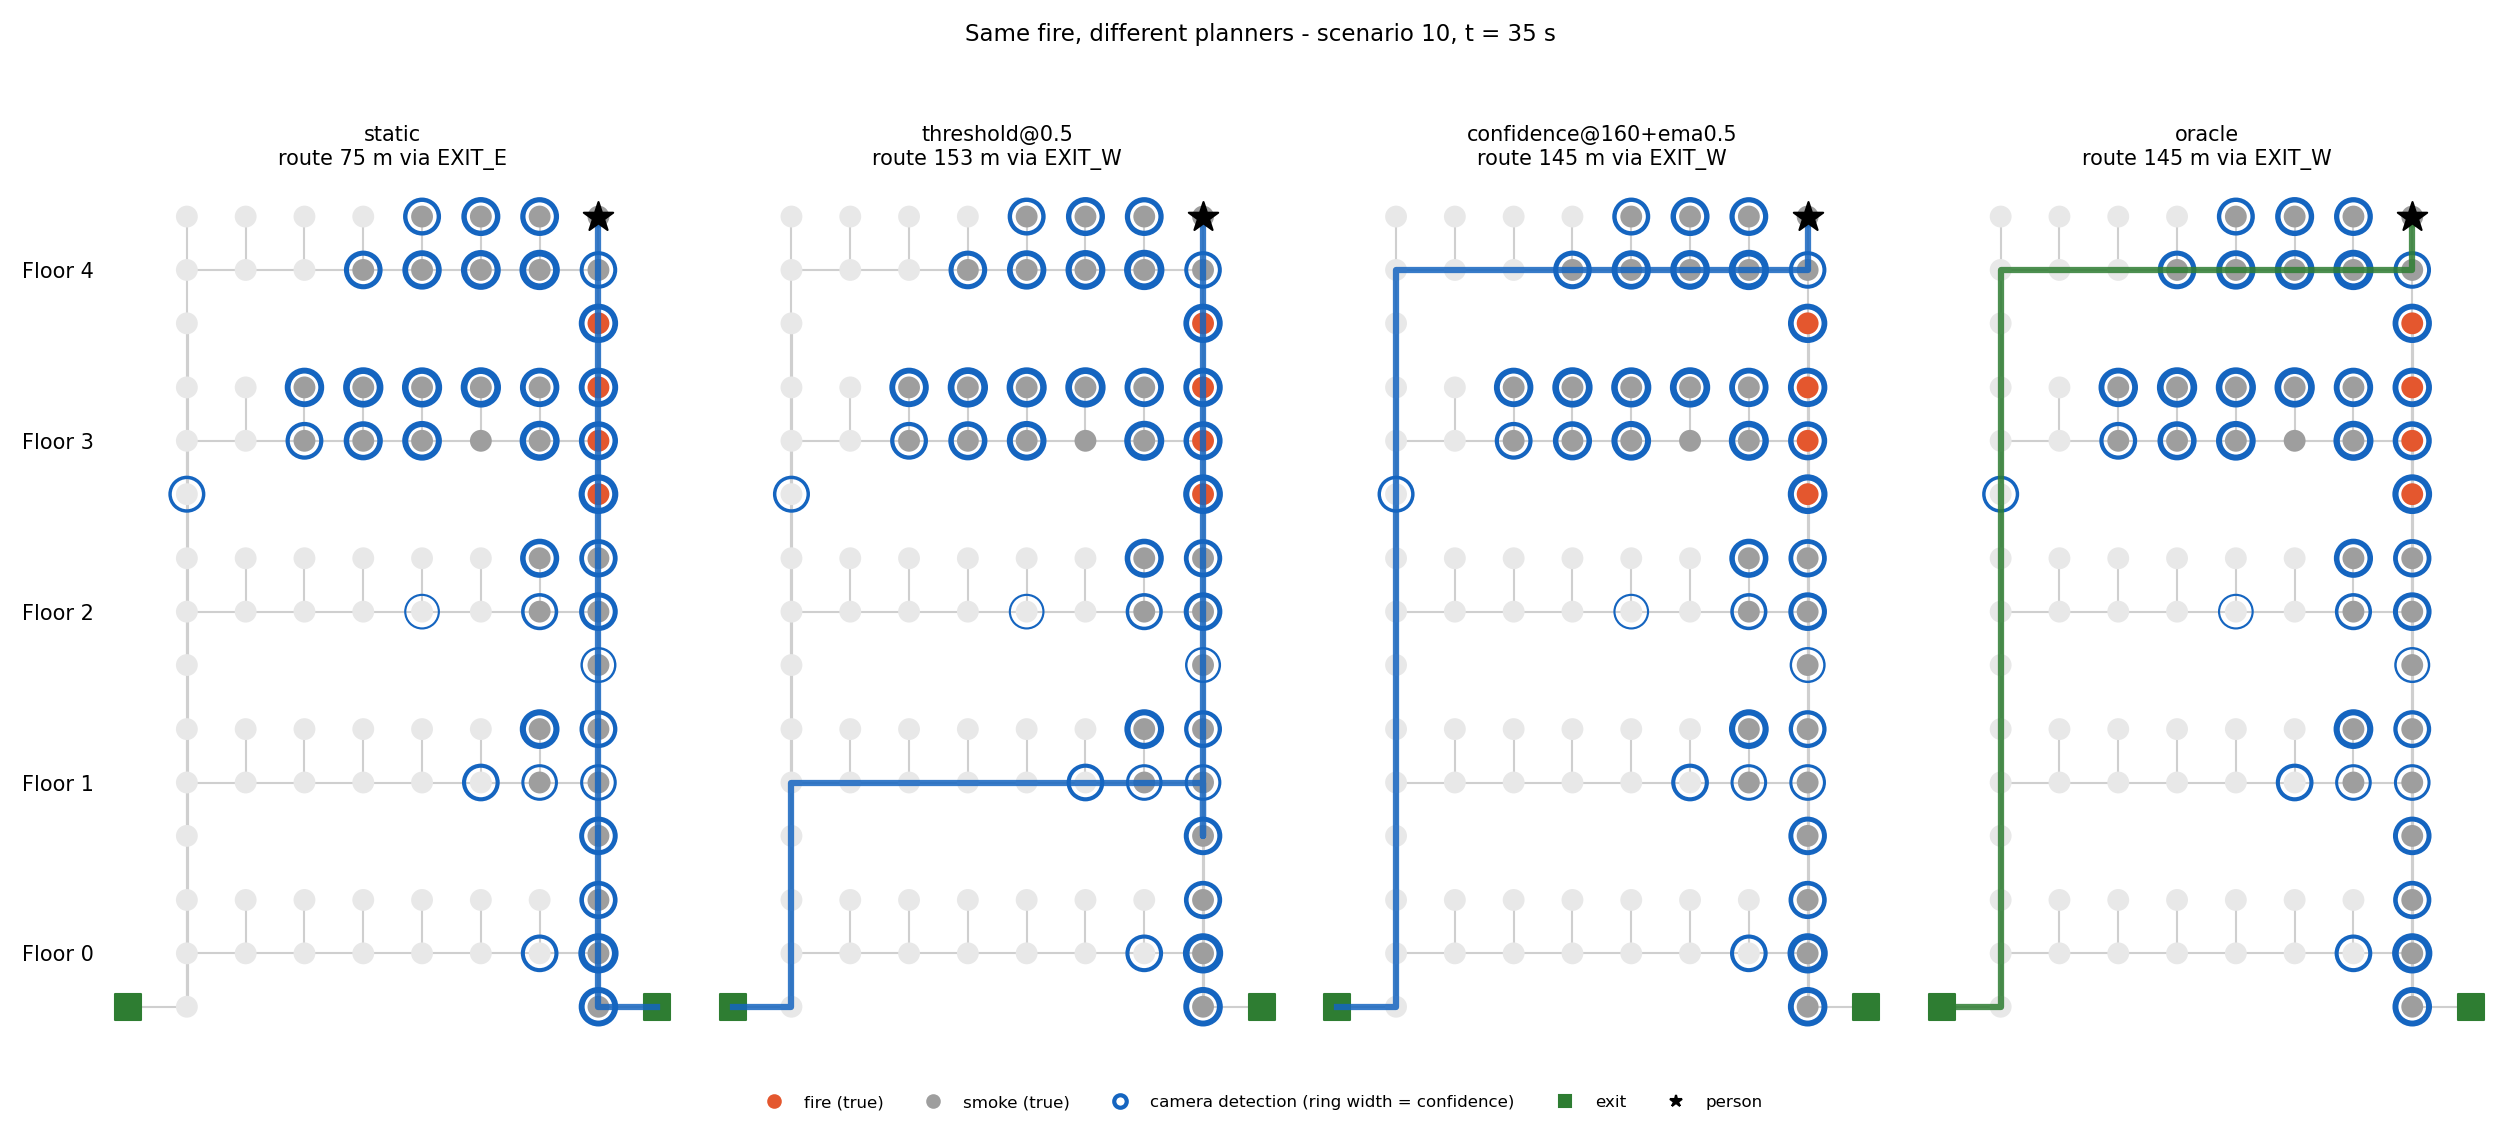

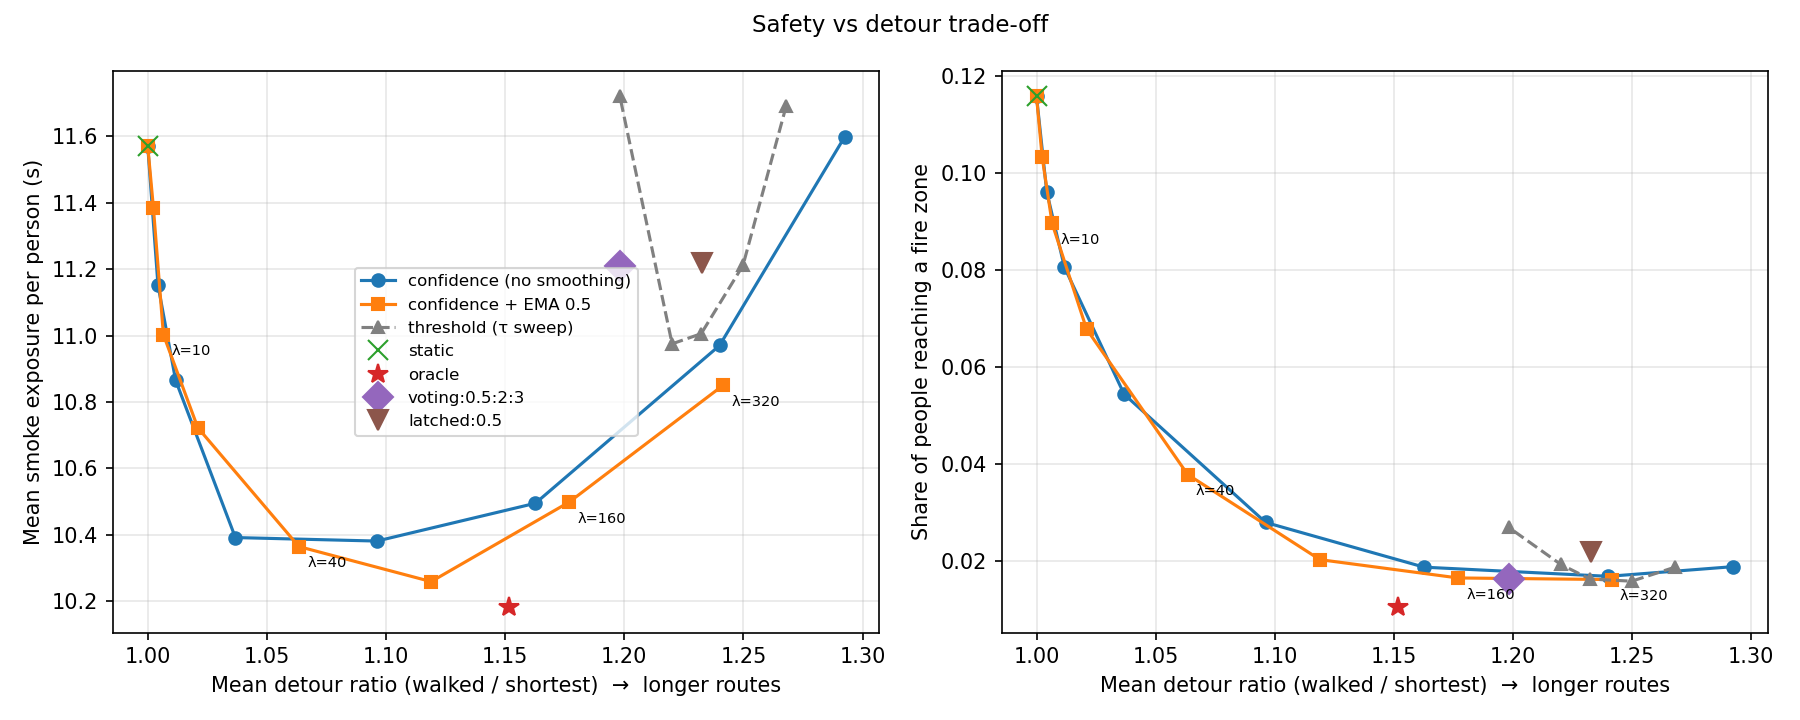

Download: shared/firepath_outputs.zip


/bin/sh: 1: zip: not found


In [10]:
import os, sys, subprocess
from IPython.display import Image, display
H = os.path.expanduser('~'); PY = sys.executable; os.chdir(f'{H}/firepath')
OUT = f'{H}/shared/firepath_outputs'

# 1. Table VI (error-type ablation) + full Table V with confidence intervals
print(open(f'{OUT}/results_test/error_types.md').read())
print(open(f'{OUT}/results_test/summary.md').read())

# 2. Fig. 3: route example with the MEASURED detector errors
r = subprocess.run([PY, '-m', 'firepath.visualize', '--find-interesting',
                    '--errors', 'configs/detector_errors_measured.json',
                    '--out', f'{OUT}/results_test/route_example.png'],
                   capture_output=True, text=True, timeout=1800)
print(r.stdout[-800:], r.stderr[-800:])
if os.path.exists(f'{OUT}/results_test/route_example.png'):
    display(Image(f'{OUT}/results_test/route_example.png'))
display(Image(f'{OUT}/results_test/tradeoff.png'))

# 3. one zip with everything, for download
subprocess.run(f'cd {H}/shared && zip -q -r firepath_outputs.zip firepath_outputs', shell=True)
print('Download: shared/firepath_outputs.zip')

In [9]:
VID = f'{BASE}/videos'
!{PY} detection/measure_detector.py --weights runs/firepath/train/weights/best.pt \
    --videos $VID/videos.csv \
    --calib-videos $VID/calib.csv \
    --out configs/detector_errors_measured.json
!cp configs/detector_errors_measured.* $BASE/saved/

NameError: name 'BASE' is not defined

## 5. Choose λ on validation scenarios, then run the real experiments

In [12]:
import shutil, os
shutil.make_archive(os.path.expanduser('~/shared/firepath_outputs'), 'zip', os.path.expanduser('~/shared'), 'firepath_outputs')
print('Download: shared/firepath_outputs.zip')

Download: shared/firepath_outputs.zip


## 6. Download your results
Right-click `saved.zip` in the file browser → Download. Optionally also copy to S3. Then **stop the space / instance**.

In [15]:
!cd $BASE && zip -q -r saved.zip saved
S3_OUT = ''   # e.g. 's3://my-bucket/firepath-results/'
if S3_OUT:
    !aws s3 cp $BASE/saved.zip $S3_OUT

/bin/bash: line 1: zip: command not found


In [16]:
!cp ~/firepath/train.log ~/shared/firepath_outputs/